# 05 · Harmonization: learning the exchange rate between sensors

> **What and why**
>
> - We put every VIIRS satellite on one scale, the NOAA-20 scale, so the record does not depend on how many satellites flew.
> - For the MODIS years we predict what NOAA-20 VIIRS would have counted, from what MODIS saw.
> - We climb a ladder of models, from a simple exchange rate to gradient boosting, and keep the one that wins on years and places it never saw.
> - Every modelled value gets a 90% range that we check on held out data.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
import json, pickle
import lightgbm as lgb
from fireharmony import harmonize as H
MODELS = REPO / 'models'

## 1. All VIIRS satellites on one scale

Suomi NPP and NOAA-21 carry the same camera as NOAA-20, but they pass at slightly different times. We learn a ratio for each region (H3 level 1, about 600,000 km2) from the months when both flew. Then we average the satellites instead of adding them, so more satellites never mean more fire.

In [2]:
b = pickle.load(open(MODELS / 'bridges.pkl', 'rb'))
for sat, name in (('S', 'Suomi NPP'), ('J', 'NOAA-21')):
    k = b['k'][sat]
    w = k.other / k.other.sum()
    print(f"{name} to NOAA-20: world ratio {k.attrs['k_global']:.3f}; regional ratios (weighted by fires) 5% to 95%: "
          f"{np.interp([0.05, 0.95], np.cumsum(w[k.k.argsort()]), np.sort(k.k)).round(3)}")

Suomi NPP to NOAA-20: world ratio 0.990; regional ratios (weighted by fires) 5% to 95%: [0.967 1.02 ]
NOAA-21 to NOAA-20: world ratio 1.046; regional ratios (weighted by fires) 5% to 95%: [1.009 1.079]


## 2. The model ladder

We compare three rungs. The exchange rate multiplies what MODIS saw by a learned rate for each region and month. Gradient boosting also uses the size and strength of the fires, the activity around each cell and its usual season, so it can also place fire where MODIS saw nothing. We also tested a reconciled model. It keeps the map of gradient boosting but scales it so the total of each large region (H3 level 1, about 600,000 km2) matches the exchange rate in that month. It scored best in the tests below, but those tests can only use 2012 to 2019. Further back in time its correction grows (by 1 to 2% in 2003 to 2011, 7% in Aqua's first year and 12.5% with Terra alone), so it would add steps to the record where the satellites change. So the record uses plain gradient boosting.

We hold out two years at a time (2012 and 2013, then 2014 and 2015, and so on). We train on the other years using one set of regions, and test on the held out years in other regions (whole H3 level 3 blocks of about 12,400 km2). So every score is for years and places the model never saw. CCC is Lin's concordance on a log scale: 1 means perfect agreement.

lin_ccc_log                                            median_abs_rel_err_pct                                              bias_pct         \
model                   gbm_t gbm_ta hybrid_t hybrid_ta ratio_t ratio_ta                  gbm_t  gbm_ta hybrid_t hybrid_ta  ratio_t ratio_ta    gbm_t gbm_ta   
scale                                                                                                                                                          
cell x month            0.831  0.898    0.837     0.900   0.526    0.720                 13.796   8.838   11.881     7.486  100.000   99.630   -1.579  -0.98   
region L4 x month       0.875  0.925    0.882     0.928   0.670    0.809                 39.190  26.055   36.251    23.453  100.000   94.749   -1.579  -0.98   
region L3 x month       0.906  0.944    0.911     0.947   0.763    0.866                 54.502  37.752   52.711    36.840  100.000   66.435   -1.579  -0.98   
continent x month       0.994  0.996    0.994     0.996   0.993    0.994                 17.181   9.900   13.235     7.634   10.316    5.681   -1.579  -0.98   
world x month           0.988  0.994    0.983     0.991   0.975    0.991                  3.235   1.891    3.391     2.503    3.972    2.505   -1.579  -0.98   
region L3 x year        0.948  0.966    0.948     0.967   0.897    0.944                 43.961  29.662   43.529    29.891   47.253   31.296   -1.579  -0.98   
continent x year        0.984  0.991    0.984     0.991   0.985    0.985                 10.346   5.465    5.315     3.552    5.241    3.031   -1.579  -0.98   

                                                       
model             hybrid_t hybrid_ta ratio_t ratio_ta  
scale                                                  
cell x month        -0.184    -1.002   1.018   -1.158  
region L4 x month   -0.184    -1.002   1.018   -1.158  
region L3 x month   -0.184    -1.002   1.018   -1.158  
continent x month   -0.184    -1.002   1.018   -1.157  
world x month       -0.184    -1.002   1.018   -1.158  
region L3 x year    -0.184    -1.002   1.018   -1.158  
continent x year    -0.184    -1.002   1.018   -1.157

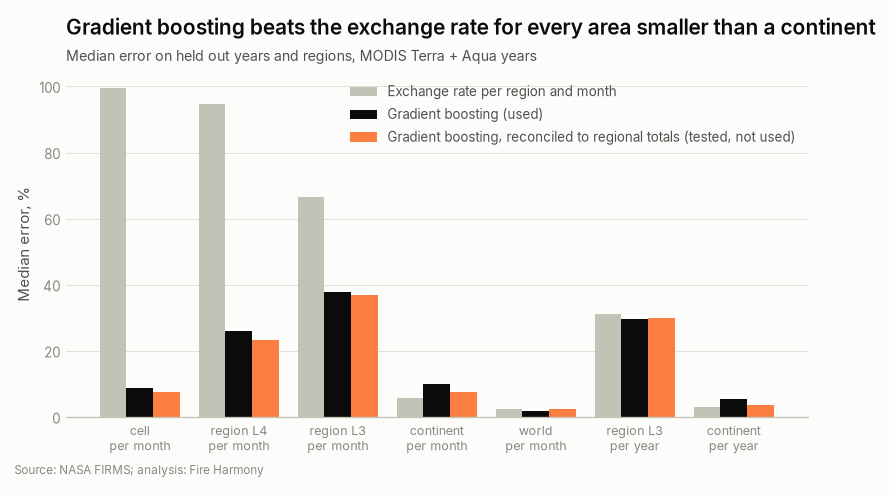

In [3]:
sc = pd.read_parquet(C.work('models', 'cv_scores.parquet'))
tab = sc.groupby(['scale', 'model'])[['lin_ccc_log', 'median_abs_rel_err_pct', 'bias_pct']].mean().unstack('model').round(3)
order = ['cell x month', 'region L4 x month', 'region L3 x month', 'continent x month', 'world x month', 'region L3 x year', 'continent x year']
tab = tab.reindex(order)
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
x = np.arange(len(order)); wd = 0.27
for i, (m, col, lab) in enumerate([('ratio_ta', fh.BASELINE, 'Exchange rate per region and month'), ('gbm_ta', fh.INK, 'Gradient boosting (used)'),
                                   ('hybrid_ta', fh.EMBER[3], 'Gradient boosting, reconciled to regional totals (tested, not used)')]):
    v = tab[('median_abs_rel_err_pct', m)].to_numpy()
    ax.bar(x + (i - 1) * wd, v, wd, color=col, label=lab)
ax.set_xticks(x, [o.replace(' x ', '\nper ') for o in order], fontsize=7.5)
fh.clean(ax); ax.set_ylabel('Median error, %'); ax.legend(frameon=False, fontsize=8)
fh.title(ax, 'Gradient boosting beats the exchange rate for every area smaller than a continent', 'Median error on held out years and regions, MODIS Terra + Aqua years')
fh.source(fig, 'Source: NASA FIRMS; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig07_model_ladder')
tab

## 3. What the model learned

The importance of a feature is how much it improved the fit in total.

T_c7             40.8
T_n              14.5
A_n              12.7
T_frp_per_det     5.5
A_c7              4.9
ctx4              4.5
A_frp_per_det     4.2
T_frp             2.7
A_frp             2.4
A_pix             1.8
A_fd              1.5
clim              1.5
ctx3              0.4
T_nl              0.3
T_nn              0.3
dtype: float64

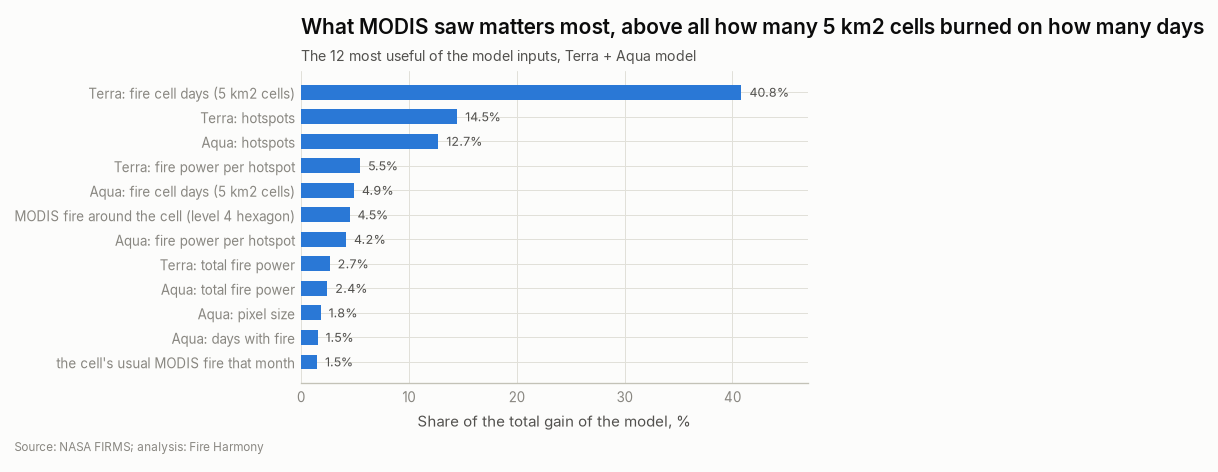

In [4]:
bst = lgb.Booster(model_file=str(MODELS / 'gbm_terra_aqua.txt'))
imp = pd.Series(bst.feature_importance('gain'), index=bst.feature_name()).sort_values()
imp = 100 * imp / imp.sum()
WHAT = {'n': 'hotspots', 'nd': 'day hotspots', 'nn': 'night hotspots', 'ns': 'weak hotspots (below 5 MW)', 'nl': 'strong hotspots (50 MW or more)',
        'frp': 'total fire power', 'fd': 'days with fire', 'c7': 'fire cell days (5 km2 cells)', 'pix': 'pixel size', 'frp_per_det': 'fire power per hotspot'}
def plain(f):
    if f in ('ctx4', 'ctx3'): return f"MODIS fire around the cell (level {f[-1]} hexagon)"
    if f == 'clim': return "the cell's usual MODIS fire that month"
    if f in ('mo_sin', 'mo_cos'): return 'time of year'
    sat, _, m = f.partition('_')
    return f"{dict(T='Terra', A='Aqua').get(sat, sat)}: {WHAT.get(m, m)}" if m else f
fig, ax = plt.subplots(figsize=(fh.SIZE['full'][0], fh.SIZE['full'][1] * 0.95))
top = imp.tail(12)
ax.barh([plain(f) for f in top.index], top.values, color=fh.SENSOR['MODIS'], height=0.6)
for y, v in enumerate(top.values):
    ax.text(v, y, f'  {v:.1f}%', va='center', fontsize=7.5, color=fh.INK_2)
fh.clean(ax, grid_axis='x'); ax.set_xlabel('Share of the total gain of the model, %'); ax.set_xlim(0, top.max() * 1.15)
fh.title(ax, 'What MODIS saw matters most, above all how many 5 km2 cells burned on how many days', 'The 12 most useful of the model inputs, Terra + Aqua model')
fh.source(fig, 'Source: NASA FIRMS; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig08_feature_importance')
imp.tail(15).round(1)[::-1]

## 4. Ranges you can trust

For any area and month, the range comes from a small table. We group held out totals by size and, for each size, we find how far predictions usually miss. We tried one smooth formula first, but it covered only half of the continent totals, so we use the table. Below, the share of held out totals that fall inside their 90% range, for each kind of area.

In [5]:
iv = json.loads((MODELS / 'area_intervals.json').read_text())
pd.DataFrame({k: v['coverage_by_scale'] for k, v in iv.items()})

,terra_aqua_month,terra_aqua_year,terra_only_month,terra_only_year
cell x month,0.952,NaN,0.947,NaN
continent x month,0.921,NaN,0.917,NaN
region L3 x month,0.926,NaN,0.939,NaN
region L4 x month,0.943,NaN,0.946,NaN
world x month,0.957,NaN,0.948,NaN
continent x year,NaN,1.000,NaN,0.984
region L3 x year,NaN,0.918,NaN,0.918


## 5. The Terra only years

Before July 2002 only Terra flew, so the record there comes from the Terra only model. Where both models ran, the Terra only model read lower in the first years after the seam, so we bridge it to the Terra + Aqua model, region by region, with ratios learned in the three years after July 2002. Notebook 06 shows why and how well it works.

In [6]:
br = json.loads((MODELS / 'terra_only_bridge.json').read_text())
k = pd.Series(br['regions'])
ym = lambda m: pd.Period(year=m // 100, month=m % 100, freq='M').strftime('%B %Y')
print(f"Terra only to Terra + Aqua, learned {ym(br['months'][0])} to {ym(br['months'][1])}: world ratio {br['k_global']:.3f}; "
      f"level 1 regions, middle 90%: {k.quantile(0.05):.2f} to {k.quantile(0.95):.2f}")

Terra only to Terra + Aqua, learned July 2002 to June 2005: world ratio 1.033; level 1 regions, middle 90%: 0.86 to 1.21


> **Key findings**
>
> - Suomi NPP and NOAA-20 agree to within 1% worldwide. NOAA-21 counts about 4% fewer fires than NOAA-20 (NOAA-20 counts 4.6% more), and we correct for it.
> - On years and regions it never saw, gradient boosting beats the simple exchange rate for every area smaller than a continent. For regions of 12,400 km2 and one month the median error falls from 66% to 38%, and the agreement (CCC) rises from 0.87 to 0.94.
> - For whole continents the exchange rate alone was better (median error 5.7% against 9.9% per month), because it is tuned on regional totals. For the whole world gradient boosting is better again (1.9% against 2.5%).
> - A reconciled model (gradient boosting scaled to the regional totals of the exchange rate) scored best at most scales in 2012 to 2019, but its correction drifts back in time. We tested it and chose not to use it.
> - The best clue is how widely MODIS saw fire. The number of small cells (H3 level 7, about 5 km2) where Terra saw fire carries 41% of the gain, more than the hotspot counts of Terra and Aqua together (27%).
> - The 90% ranges hold. Between 92% and 96% of held out monthly totals fall inside them, for every size of area, and 92% to 100% of yearly totals.
> - The model is slightly low overall: by 1.0% with Terra and Aqua, and by 1.6% with Terra alone.
> - Before July 2002 the Terra only model is bridged to the Terra + Aqua model (world ratio 1.033), so the record does not step when Aqua joins.